# Lesson 2. Measurement and the Born rule

**Goal:** understand exactly what a measurement gives, what collapse is, and where histograms of "shots" come from.

## 1. The Born rule

For the state $v = (\alpha, \beta)$, a measurement in the basis $\{e_0, e_1\}$ gives:

$$P(0) = |\alpha|^2 = |\langle e_0, v\rangle|^2, \qquad P(1) = |\beta|^2 = |\langle e_1, v\rangle|^2.$$

The Born rule assigns to a state a **probability distribution of measurement outcomes**. The distribution has two points (outcomes 0 and 1) and can be degenerate (for $e_0$, $P(0) = 1$). The condition $|\alpha|^2 + |\beta|^2 = 1$ is simply the condition that the probabilities add up to one.

> **This was tricky:** it is a distribution of **outcomes**, not of states. We know the state completely; there is nothing random about it. Only the outcome is random.

## 2. What a single measurement really gives

**One outcome: 0 or 1. Nothing more.** Not two numbers, not an in-between result such as 0.49.

For a state with $P(0) = 0.49$ and $P(1) = 0.51$:

- one measurement gives 0 or 1, at random;
- **it is not an argmax**: 49% of the time you get 0, even though $0.49 < 0.51$;
- to see the numbers 0.49 and 0.51 you must prepare the same state **many times** and measure each time. These are **shots**.

There are two ways to know the probabilities:

- **theory / simulator:** we know the state, so we compute $|\alpha|^2$ exactly;
- **real hardware:** the state is invisible, so we **estimate** $|\alpha|^2$ from outcome frequencies. The standard error of the estimate is $\sqrt{p(1-p)/N} \le 0.5/\sqrt{N}$ for $N$ shots (at most about ±1.6 percentage points for 1000 shots).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
GREEN, DARK, LIGHT, GREY, ORANGE = "#44B749", "#1A8A1F", "#96E199", "#8A8A8A", "#E08A00"

e0 = np.array([1, 0], dtype=complex)   # label |0⟩
e1 = np.array([0, 1], dtype=complex)   # label |1⟩

def norm(v):
    return np.sqrt(np.sum(np.abs(v) ** 2))

def show(v, n=None):
    """Print a state vector with bit labels (label = position written in binary)."""
    v = np.asarray(v)
    n = n or int(np.log2(len(v)))
    for k, a in enumerate(v):
        if abs(a) > 1e-12:
            print(f"  position {k} ({format(k, f'0{n}b')}): amplitude {np.round(a, 3)}, P = {abs(a)**2:.3f}")

rng = np.random.default_rng(7)
alpha, beta = np.sqrt(0.49), np.sqrt(0.51)
p0 = abs(alpha) ** 2

print("Five single measurements:", rng.choice([0, 1], size=5, p=[p0, 1 - p0]))

for N in (10, 100, 1000, 100_000):
    outcomes = rng.choice([0, 1], size=N, p=[p0, 1 - p0])
    print(f"N = {N:>6}: estimated P(0) = {np.mean(outcomes == 0):.3f}   (true: {p0:.2f})")

Five single measurements: [1 1 1 0 0]
N =     10: estimated P(0) = 0.600   (true: 0.49)
N =    100: estimated P(0) = 0.460   (true: 0.49)
N =   1000: estimated P(0) = 0.501   (true: 0.49)
N = 100000: estimated P(0) = 0.489   (true: 0.49)

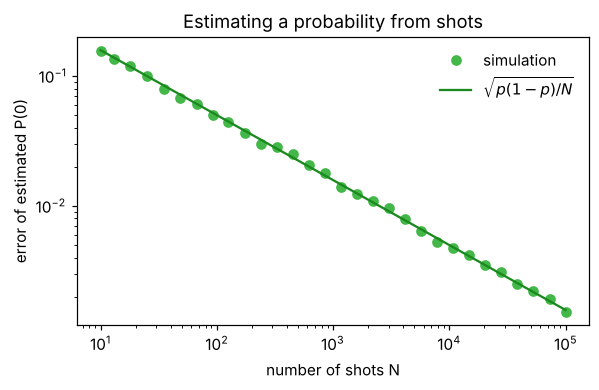

In [2]:
# How fast does the estimation error shrink? Like 1/sqrt(N).
Ns = np.unique(np.logspace(1, 5, 30).astype(int))
errors = []
for N in Ns:
    trials = rng.binomial(N, p0, size=400) / N          # 400 repetitions of an N-shot experiment
    errors.append(np.std(trials))

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.loglog(Ns, errors, "o", color=GREEN, label="simulation")
ax.loglog(Ns, np.sqrt(p0 * (1 - p0) / Ns), color=DARK, label=r"$\sqrt{p(1-p)/N}$")
ax.set_xlabel("number of shots N"); ax.set_ylabel("error of estimated P(0)")
ax.legend(frameon=False); ax.set_title("Estimating a probability from shots")

## 3. Collapse

Collapse describes what happens to the **state after measurement**: if the outcome is 0, the state becomes $e_0$; if 1, it becomes $e_1$. The superposition disappears, and with it the information about $\alpha$ and $\beta$.

Mathematically it is a projection followed by normalisation. The projection onto $e_0$ is the matrix $P_0 = e_0 e_0^{*} = \begin{pmatrix}1 & 0\\ 0 & 0\end{pmatrix}$, and the new state is

$$v \;\longmapsto\; \frac{P_0 v}{\|P_0 v\|} = \frac{(\alpha, 0)}{|\alpha|} \simeq e_0 \quad\text{(up to phase).}$$

You can see it experimentally: a second measurement right after the first gives the **same** outcome with certainty.

In [3]:
def measure(v, rng):
    """Measurement in the basis {e0, e1}: draws an outcome by the Born rule and returns (outcome, state after collapse)."""
    p = np.abs(v) ** 2
    k = rng.choice(len(v), p=p)
    after = np.zeros_like(v); after[k] = v[k] / abs(v[k])   # project onto e_k and normalise
    return k, after

v = np.array([np.sqrt(0.49), np.sqrt(0.51)], dtype=complex)
for trial in range(4):
    k1, after = measure(v, rng)
    k2, _ = measure(after, rng)
    print(f"first measurement: {k1}, state after it: {np.round(after, 3)}, second measurement: {k2}")

first measurement: 0, state after it: [1.+0.j 0.+0.j], second measurement: 0
first measurement: 1, state after it: [0.+0.j 1.+0.j], second measurement: 1
first measurement: 1, state after it: [0.+0.j 1.+0.j], second measurement: 1
first measurement: 1, state after it: [0.+0.j 1.+0.j], second measurement: 1

## 4. Measurement is not reading a pre-existing value

> **This was tricky:** it is natural to think "the system was 0 or 1, and measurement checked which". That is not how it works.

- Before measurement the system is in the state $(\alpha, \beta)$, not in 0 or 1.
- Measurement **produces** an outcome 0 or 1, drawn with the distribution $|\alpha|^2, |\beta|^2$.
- Measurement **changes** the state to the one that came out.
- The values $\alpha$ and $\beta$ themselves cannot be read out.

A thermometer shows a temperature that existed before the measurement. Measuring a qubit creates the outcome. Lesson 3 shows that a superposition is not a hidden $e_0$ or $e_1$ (state $u_+$ versus a classical coin); that no hidden-value model works at all is the content of Bell's theorem (lesson 7).

**Physically, in a transmon:** the qubit is coupled to a microwave resonator whose frequency shifts slightly depending on the qubit's state. A weak probe pulse is sent and the phase of the reflected signal is measured; electronics classify it as 0 or 1. About 1% of the time the classification is wrong (readout error, the second half of SPAM).

**What is collapse "really"?** It is an open question in physics (the measurement problem). In the standard view it is a postulate consistent with every experiment; decoherence explains much of it, but not why this particular outcome occurs. For programming quantum computers three rules suffice: the outcome is random, the distribution is $|\text{amplitude}|^2$, and after measurement the state is whatever came out.

## Summary

> We have a physical two-level system. We describe its state with a unit vector $(\alpha, \beta) \in \mathbb{C}^2$, which we know from how we prepared the system. A measurement gives 0 or 1, drawn from the distribution determined by the state: $P(0) = |\alpha|^2$, $P(1) = |\beta|^2$. After measurement the system is in the state corresponding to the outcome (collapse). The model predicts the **statistics** of outcomes, not a single outcome, and that is not a flaw: in the standard interpretation of quantum mechanics a single outcome is not determined in advance.

Gates (lesson 5) change the state **deterministically**. Only measurement is random.

## Exercises

1. A state has $P(0) = 0.49$ and $P(1) = 0.51$. One measurement gave 0. What is the state right after the measurement? What will a second measurement give?
2. 1000 shots gave 487 zeros and 513 ones. What $|\alpha|^2$ and $|\beta|^2$ do you estimate, and with what error? Can you read the sign of $\beta$ from this?
3. Grover's circuit on ibm_marrakesh (secret 101): 783 hits in 1000 shots. What is the statistical error of this number? Can it explain the gap to 0.945 from the simulator?